# 13 · Two-stage models

Does a first model that produces something (tier probabilities, residuals, a promo score, a community) help a second model refine the estimate? Target log10(views) on TikTok, YouTube and X, brand-grouped 5-fold CV. Base: CatBoost, library defaults (300 iterations, RMSE loss), features followers + reactions + missing flags. Plan item G.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, modeling as mo, stacked_models as sm

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 60)

## 1 · Run (or load) the out-of-fold predictions

Every first-stage output used by a second stage is out-of-fold inside the training fold (inner 5-fold split by brand). Tier thresholds come from the training fold. The run is cached in `data/processed/stacked_cache.pkl`; delete it to recompute (about 20-40 minutes).

In [2]:
R = sm.run_all(ROOT, ROOT / 'data' / 'processed' / 'stacked_cache.pkl')
{eu.NAMES[p]: (len(r['y']), len(np.unique(r['g'])), int(r['zr'].sum()), r['n_comm']) for p, r in R.items()}  # mentions, brands, zero-reaction posts, text communities

{'TikTok': (2491, 266, 84, 37),
 'YouTube': (2441, 273, 665, 42),
 'X (Twitter)': (1803, 252, 973, 27)}

## 2 · First-stage quality

In [3]:
Q = sm.stage_quality(R); Q.round(3)

,platform,stage,macro F1,AUC,chance F1,n,AP,prevalence
0,TikTok,A: tier (low / middle / top),0.776,0.915,0.327,2491,NaN,NaN
1,TikTok,D: promo from text,0.666,0.828,NaN,2491,0.710,0.339
2,YouTube,A: tier (low / middle / top),0.744,0.897,0.333,2441,NaN,NaN
3,YouTube,D: promo from text,0.752,0.838,NaN,2441,0.771,0.425
4,X (Twitter),A: tier (low / middle / top),0.596,0.774,0.311,1803,NaN,NaN
5,X (Twitter),D: promo from text,0.520,0.882,NaN,1803,0.597,0.185


## 3 · Overall error and paired gain over the base

In [4]:
S = sm.summarize(R)
S.pivot(index='approach', columns='platform', values='MAE').reindex(sm.APPROACHES)[[eu.NAMES[p] for p in mo.PLATS]].round(3)

platform,TikTok,YouTube,X (Twitter)
approach,,,
base,0.285,0.463,0.488
base (MAE loss),0.273,0.456,0.466
A1 tier probabilities as features,0.286,0.470,0.484
"A2 tier-routed, soft weights",0.286,0.462,0.485
B1 residual on text,0.296,0.472,0.498
B2 residual on our labels,0.296,0.483,0.504
B3 residual on text + labels,0.293,0.475,0.491
C1 hurdle: zero-reaction branch,0.288,0.463,0.495
C2 hurdle + text in that branch,0.286,0.460,0.479


In [5]:
g = S.assign(txt=lambda d: d.gain.map('{:+.4f}'.format) + ' [' + d['gain low'].map('{:+.4f}'.format) + ', ' + d['gain high'].map('{:+.4f}'.format) + ']')
g.pivot(index='approach', columns='platform', values='txt').reindex(sm.APPROACHES)[[eu.NAMES[p] for p in mo.PLATS]]

platform,TikTok,YouTube,X (Twitter)
approach,,,
base,"+0.0000 [+0.0000, +0.0000]","+0.0000 [+0.0000, +0.0000]","+0.0000 [+0.0000, +0.0000]"
base (MAE loss),"+0.0114 [+0.0069, +0.0158]","+0.0069 [-0.0012, +0.0148]","+0.0218 [+0.0135, +0.0302]"
A1 tier probabilities as features,"-0.0011 [-0.0050, +0.0030]","-0.0074 [-0.0172, +0.0024]","+0.0047 [-0.0047, +0.0142]"
"A2 tier-routed, soft weights","-0.0010 [-0.0035, +0.0018]","+0.0007 [-0.0032, +0.0048]","+0.0032 [-0.0004, +0.0070]"
B1 residual on text,"-0.0118 [-0.0178, -0.0065]","-0.0090 [-0.0187, +0.0006]","-0.0096 [-0.0188, +0.0003]"
B2 residual on our labels,"-0.0117 [-0.0170, -0.0063]","-0.0202 [-0.0283, -0.0117]","-0.0154 [-0.0249, -0.0070]"
B3 residual on text + labels,"-0.0082 [-0.0139, -0.0028]","-0.0125 [-0.0221, -0.0031]","-0.0031 [-0.0135, +0.0069]"
C1 hurdle: zero-reaction branch,"-0.0032 [-0.0063, -0.0001]","-0.0008 [-0.0078, +0.0062]","-0.0070 [-0.0134, -0.0002]"
C2 hurdle + text in that branch,"-0.0010 [-0.0040, +0.0020]","+0.0024 [-0.0070, +0.0120]","+0.0095 [+0.0000, +0.0190]"


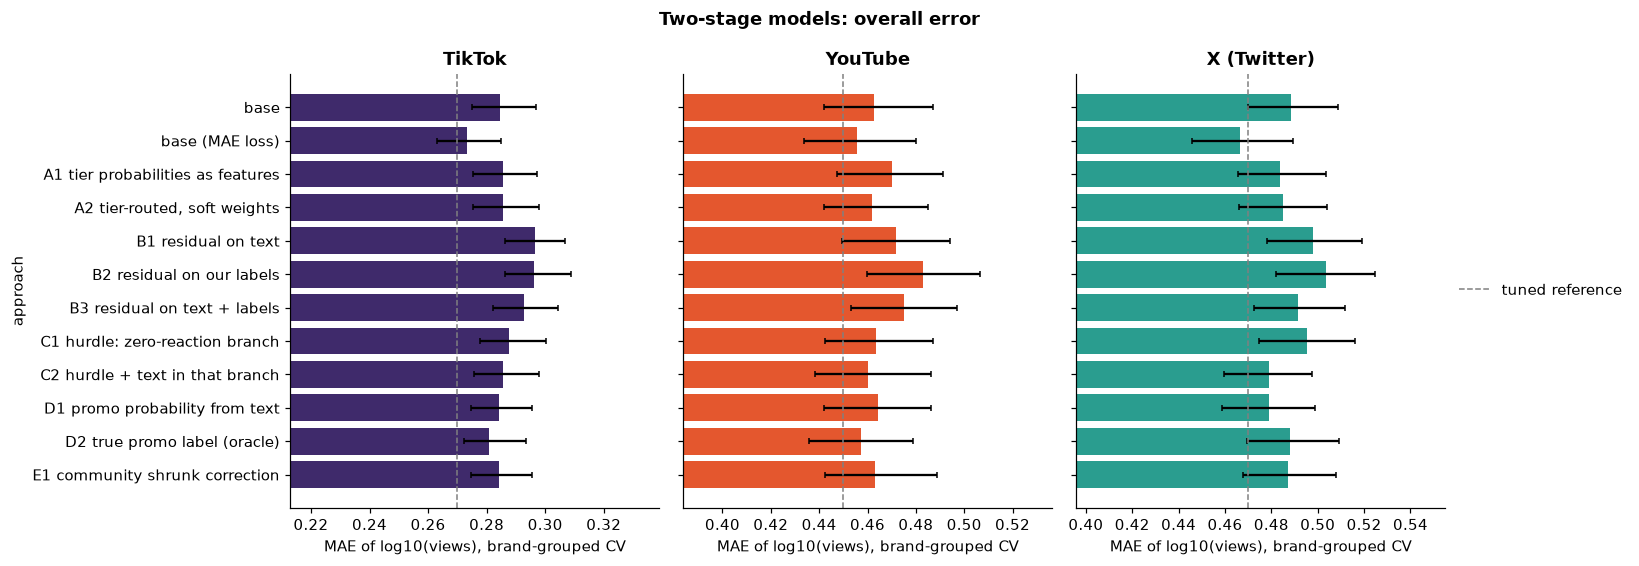

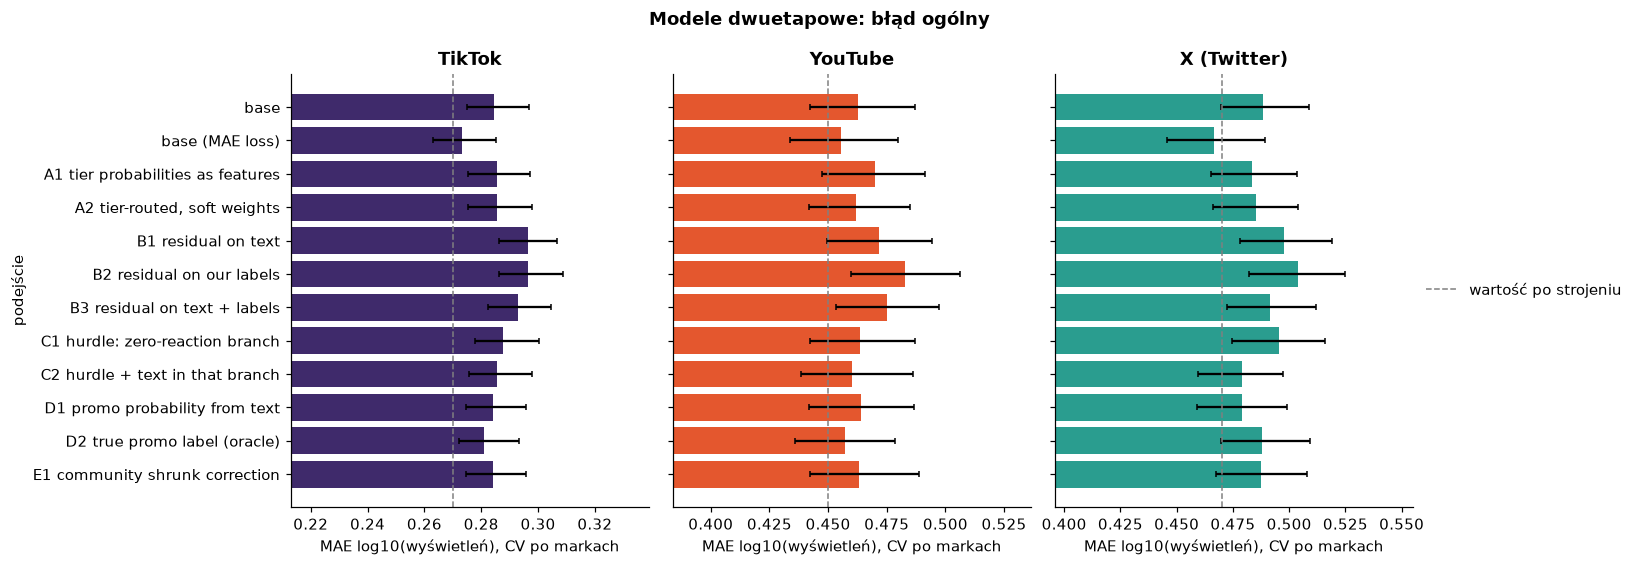

In [6]:
for lang in ['en', 'pl']: sm.plot_mae(S, lang, FIG / f'stacked_mae_{lang}.png')

## 4 · The extremes and posts without reactions

Gain is the mean of base absolute error minus new absolute error, so positive is better. Fifths are cut on the true views of each platform.

In [7]:
seg = ['lowest fifth', 'top fifth', 'zero reactions']
rows = []
for _, r in S.iterrows():
    for s in seg:
        if f'{s} gain' in r and pd.notna(r[f'{s} gain']): rows.append({'platform': r.platform, 'approach': r.approach, 'segment': s, 'MAE': r[f'{s} MAE'], 'gain': r[f'{s} gain'], 'low': r[f'{s} gain low'], 'high': r[f'{s} gain high'], 'bias (pred - true)': r[f'{s} bias']})
E = pd.DataFrame(rows); E[E.approach.isin(['base']+sm.APPROACHES[2:])].round(3).set_index(['platform', 'segment', 'approach'])

MAE   gain    low   high  bias (pred - true)
platform    segment        approach                                                                         
TikTok      lowest fifth   base                               0.338  0.000  0.000  0.000               0.222
            top fifth      base                               0.358  0.000  0.000  0.000              -0.179
            zero reactions base                               0.558  0.000  0.000  0.000               0.010
            lowest fifth   A1 tier probabilities as features  0.345 -0.007 -0.019  0.004               0.237
            top fifth      A1 tier probabilities as features  0.358 -0.000 -0.010  0.009              -0.192
...                                                             ...    ...    ...    ...                 ...
X (Twitter) top fifth      D2 true promo label (oracle)       0.679 -0.000 -0.015  0.016              -0.523
            zero reactions D2 true promo label (oracle)       0.514 -0.001 -0.007  0.005               0.002
            lowest fifth   E1 community shrunk correction     0.705  0.006 -0.008  0.019               0.701
            top fifth      E1 community shrunk correction     0.672  0.007 -0.004  0.018              -0.526
            zero reactions E1 community shrunk correction     0.511  0.002 -0.004  0.008              -0.004

[99 rows x 5 columns]

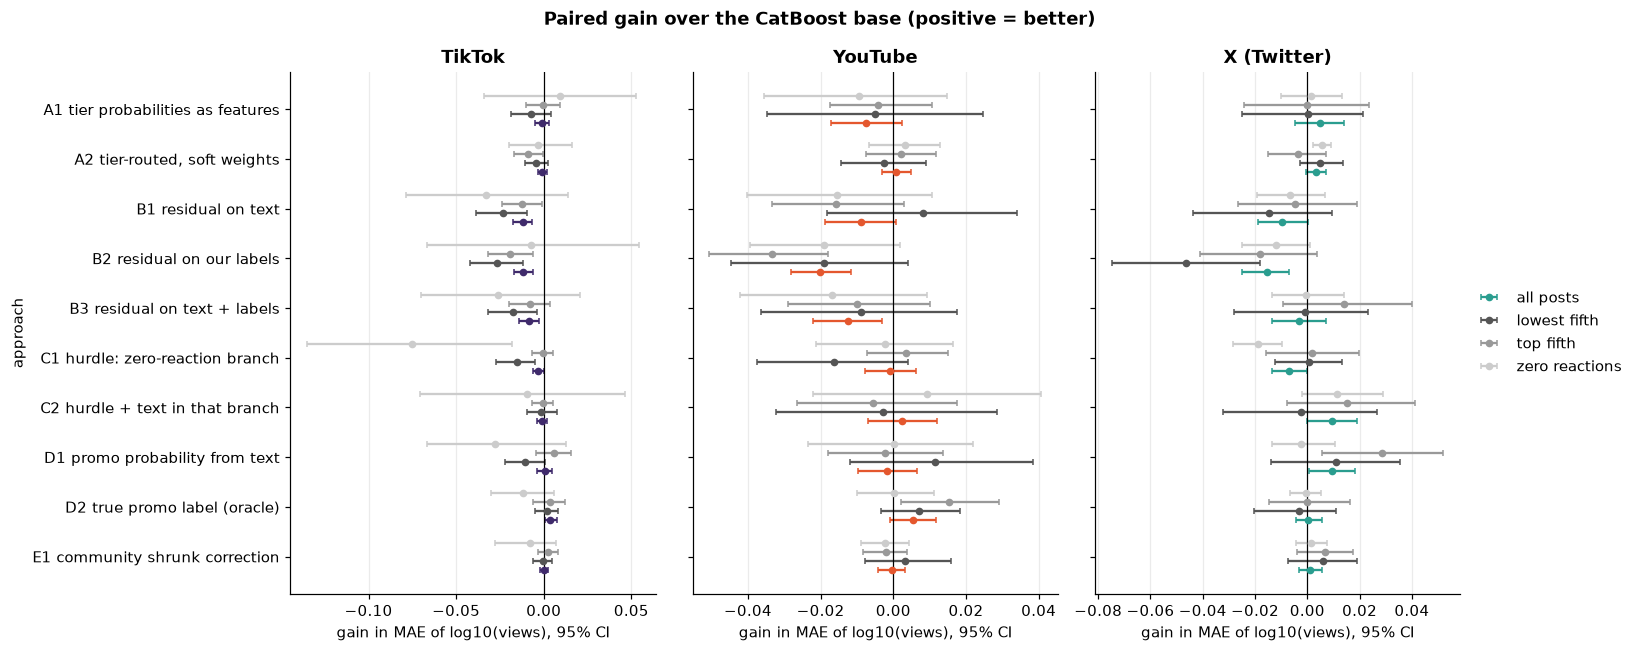

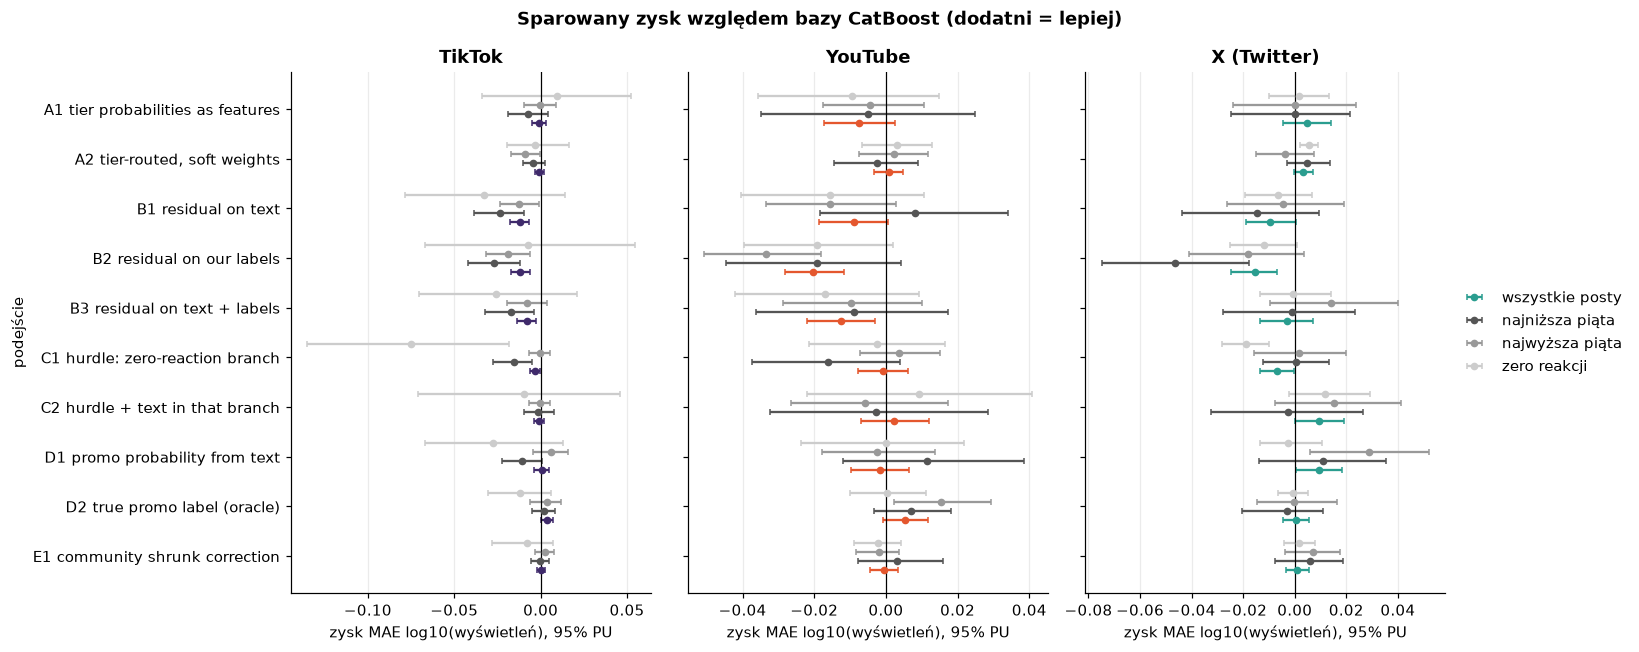

In [8]:
for lang in ['en', 'pl']: sm.plot_gain(S, lang, FIG / f'stacked_gain_{lang}.png')

## 5 · Error per fifth of true views and the trade-off

A model that spreads its predictions can lower the error at the ends and raise it in the middle. Spread of predictions against spread of true values is shown for reference.

In [9]:
cols = ['fifth1 MAE', 'fifth2 MAE', 'fifth3 MAE', 'fifth4 MAE', 'fifth5 MAE', 'MAE', 'pred sd', 'true sd']
S.set_index(['platform', 'approach'])[cols].round(3)

fifth1 MAE  fifth2 MAE  fifth3 MAE  fifth4 MAE  fifth5 MAE    MAE  pred sd  true sd
platform    approach                                                                                                              
TikTok      base                                    0.338       0.210       0.223       0.294       0.358  0.285    0.834    0.905
            base (MAE loss)                         0.321       0.178       0.210       0.293       0.363  0.273    0.798    0.905
            A1 tier probabilities as features       0.345       0.210       0.217       0.298       0.358  0.286    0.826    0.905
            A2 tier-routed, soft weights            0.342       0.205       0.219       0.295       0.367  0.286    0.834    0.905
            B1 residual on text                     0.361       0.225       0.226       0.300       0.370  0.296    0.823    0.905
            B2 residual on our labels               0.365       0.215       0.226       0.298       0.377  0.296    0.829    0.905
            B3 residual on text + labels            0.355       0.221       0.224       0.298       0.366  0.293    0.827    0.905
            C1 hurdle: zero-reaction branch         0.353       0.208       0.220       0.298       0.358  0.288    0.839    0.905
            C2 hurdle + text in that branch         0.339       0.211       0.220       0.298       0.358  0.286    0.834    0.905
            D1 promo probability from text          0.349       0.209       0.223       0.288       0.352  0.284    0.831    0.905
            D2 true promo label (oracle)            0.336       0.210       0.218       0.285       0.354  0.281    0.831    0.905
            E1 community shrunk correction          0.338       0.207       0.224       0.296       0.356  0.284    0.837    0.905
YouTube     base                                    0.598       0.412       0.356       0.414       0.533  0.463    1.034    1.183
            base (MAE loss)                         0.586       0.377       0.339       0.413       0.562  0.456    0.995    1.183
            A1 tier probabilities as features       0.603       0.412       0.375       0.422       0.537  0.470    1.034    1.183
            A2 tier-routed, soft weights            0.601       0.402       0.363       0.412       0.530  0.462    1.039    1.183
            B1 residual on text                     0.590       0.424       0.365       0.430       0.548  0.472    1.044    1.183
            B2 residual on our labels               0.617       0.438       0.364       0.429       0.566  0.483    1.023    1.183
            B3 residual on text + labels            0.607       0.426       0.366       0.434       0.542  0.475    1.043    1.183
            C1 hurdle: zero-reaction branch         0.614       0.404       0.356       0.413       0.529  0.463    1.047    1.183
            C2 hurdle + text in that branch         0.601       0.389       0.359       0.414       0.538  0.460    1.028    1.183
            D1 promo probability from text          0.587       0.419       0.363       0.416       0.535  0.464    1.043    1.183
            D2 true promo label (oracle)            0.591       0.410       0.356       0.411       0.517  0.457    1.034    1.183
            E1 community shrunk correction          0.595       0.414       0.359       0.413       0.534  0.463    1.036    1.183
X (Twitter) base                                    0.711       0.321       0.295       0.485       0.678  0.488    0.623    0.851
            base (MAE loss)                         0.672       0.281       0.268       0.482       0.677  0.466    0.598    0.851
            A1 tier probabilities as features       0.710       0.310       0.286       0.483       0.679  0.484    0.628    0.851
            A2 tier-routed, soft weights            0.706       0.308       0.295       0.484       0.682  0.485    0.622    0.851
            B1 residual on text                     0.725       0.346       0.306       0.476       0.683  0.498    0

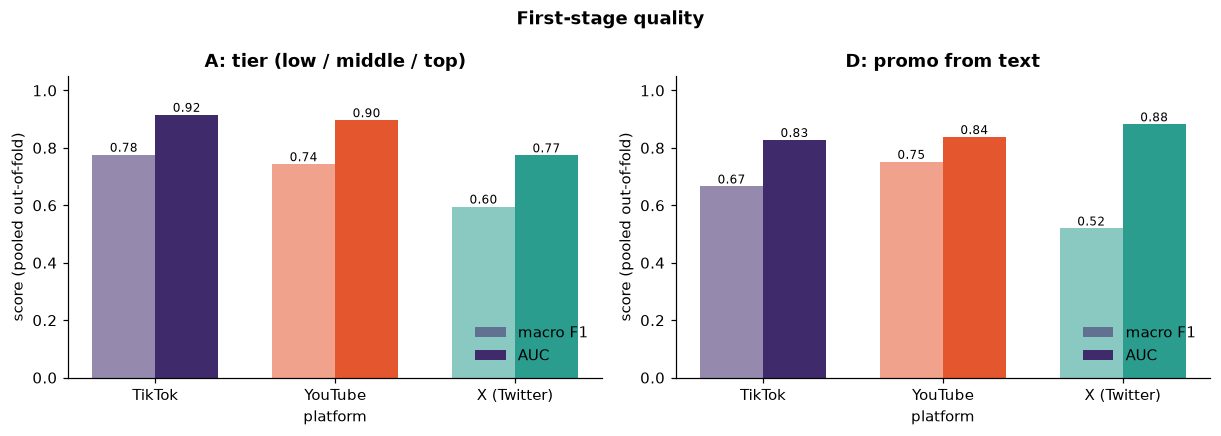

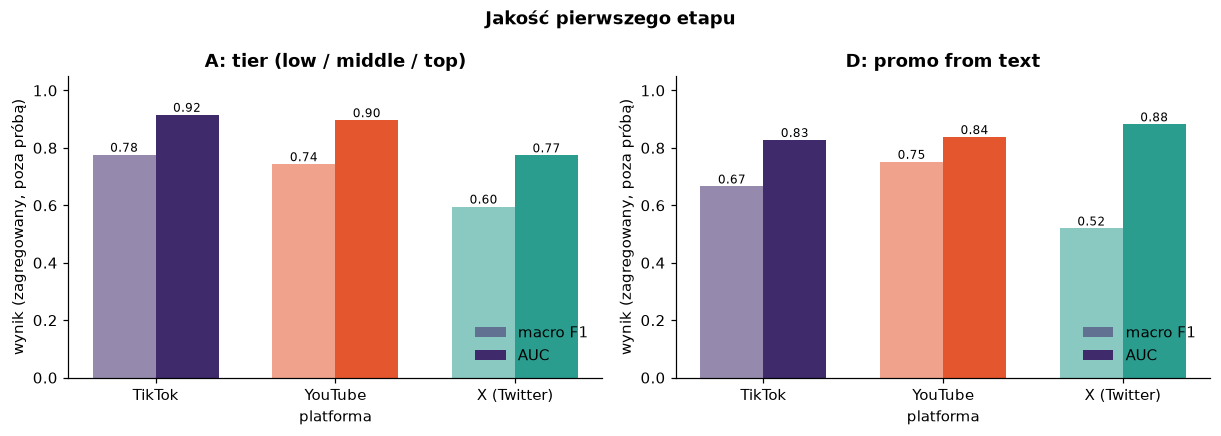

In [10]:
for lang in ['en', 'pl']: sm.plot_stage(Q, lang, FIG / f'stacked_stage1_{lang}.png')

## 6 · Save numbers

In [11]:
def clean(d): return json.loads(d.round(5).to_json(orient='records'))
out = {'setup': {'base': 'CatBoost, 300 iterations, RMSE loss, library defaults; features followers + reactions + missing flags', 'tuned_reference': sm.TUNED, 'shrink_m': sm.SHRINK, 'tiers': 'bottom 20% / middle 60% / top 20% of training-fold log10 views', 'communities': {eu.NAMES[p]: r['n_comm'] for p, r in R.items()}},
       'first_stage': clean(Q), 'summary': clean(S.drop(columns=['key']))}
(ROOT / 'data' / 'processed' / 'stacked_numbers.json').write_text(json.dumps(out, indent=1))
S.groupby('approach').gain.max().sort_values().tail(3)

approach
D1 promo probability from text     0.009359
C2 hurdle + text in that branch    0.009463
base (MAE loss)                    0.021815
Name: gain, dtype: float64

## Takeaways

- Nothing helped reliably. Tier probabilities, tier routing, residual stacking (text, our labels), a zero-reaction hurdle, a text-only promo score and community corrections all land within about +-0.01 of the base; the paired CIs mostly contain zero.
- Residual stacking on text and our labels is worse on every platform (up to -0.02 overall, -0.046 on the lowest fifth of X): the second model fits noise.
- Two small positives on X (promo from text +0.009, hurdle with text +0.009) have CIs that barely clear zero, and 33 platform-approach pairs were tested, so treat them as chance until repeated.
- The true promo label (oracle) gives at most +0.005, so even perfect first-stage promo detection would not move the error.
- Tier classification is good on TikTok and YouTube (AUC 0.90-0.92) but that knowledge is already in reactions, so the second stage gains nothing; the extremes stay hard.
- Switching the base from RMSE to MAE loss gains more than any two-stage idea (+0.011, +0.007, +0.022), mostly in the lowest fifth and the middle. Stage 2 models here all use RMSE (fixed in advance), so MAE-loss stacking was not tried.
- No approach reduced the pull to the middle: the spread of predictions stays at 0.83 / 1.03 / 0.62 against true 0.91 / 1.18 / 0.85.